# 05 · Milestone 2 results

Every model was trained on the same train split, tuned and thresholded on validation, and scored **once** on the same test split (35,130 URLs, no site owner shared with training). Each notebook saves its test scores to `results/*.json`; this notebook only reads them.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from phishguard.evaluate import load_results

results = load_results()
results["errors"] = results["fp"] + results["fn"]
table = results[["model", "features", "accuracy", "precision", "recall", "f1", "roc_auc", "errors", "fp", "fn"]]
table.style.format({c: "{:.4%}" for c in ["accuracy", "precision", "recall", "f1"]} | {"roc_auc": "{:.5f}"}).hide(axis="index")

model,features,accuracy,precision,recall,f1,roc_auc,errors,fp,fn
XGBoost (all columns),all provided columns,100.0000%,100.0000%,100.0000%,100.0000%,1.00000,0,0,0
Random Forest (all columns),all provided columns,99.9972%,99.9933%,100.0000%,99.9966%,1.00000,1,1,0
LogReg (all columns),all provided columns,99.9943%,99.9866%,100.0000%,99.9933%,1.00000,2,2,0
Average: n-gram + XGBoost (URL only),raw URL + URL features,99.7068%,99.9258%,99.3828%,99.6536%,0.99859,103,11,92
Char n-gram LogReg (raw URL),raw URL,99.6954%,99.8787%,99.4030%,99.6403%,0.99874,107,18,89
Random Forest (URL features),URL features,99.6812%,99.9662%,99.2822%,99.6230%,0.99746,112,5,107
XGBoost (URL features),URL features,99.6755%,99.9460%,99.2889%,99.6164%,0.99707,114,8,106


## Compared with published work

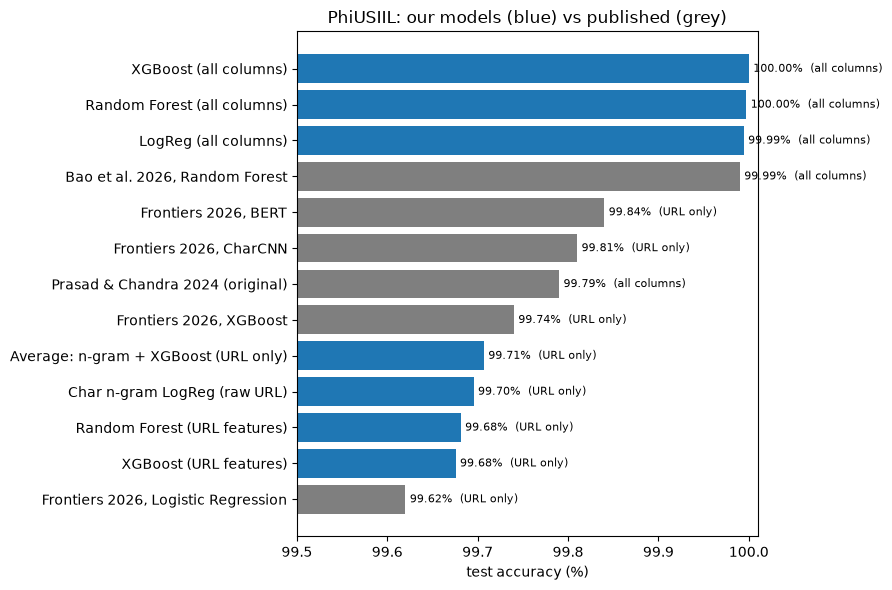

In [2]:
published = pd.DataFrame([
    ("Prasad & Chandra 2024 (original)", "all columns", 0.9979),
    ("Bao et al. 2026, Random Forest", "all columns", 0.9999),
    ("Frontiers 2026, Logistic Regression", "URL only", 0.9962),
    ("Frontiers 2026, XGBoost", "URL only", 0.9974),
    ("Frontiers 2026, CharCNN", "URL only", 0.9981),
    ("Frontiers 2026, BERT", "URL only", 0.9984),
], columns=["model", "input", "accuracy"])

ours = results.assign(input=results["features"].map(
    lambda f: "all columns" if f == "all provided columns" else "URL only"))[["model", "input", "accuracy"]]
both = pd.concat([ours.assign(source="ours"), published.assign(source="published")])

fig, ax = plt.subplots(figsize=(9, 6))
both = both.sort_values("accuracy")
colors = both["source"].map({"ours": "tab:blue", "published": "tab:gray"})
ax.barh(both["model"], both["accuracy"] * 100, color=colors)
ax.set_xlim(99.5, 100.01)
ax.set_xlabel("test accuracy (%)")
ax.set_title("PhiUSIIL: our models (blue) vs published (grey)")
for i, (acc, inp) in enumerate(zip(both["accuracy"], both["input"])):
    ax.text(acc * 100 + 0.005, i, f"{acc:.2%}  ({inp})", va="center", fontsize=8)
plt.tight_layout()
plt.show()

Published numbers come from different splits, so the comparison is indicative, not exact. The Frontiers paper also used a host-disjoint split, like ours.

## What we can say
1. **Target reached:** on all provided columns, every model scores ≥ 99.99% on test. That matches or beats the published results, using a stricter split than most papers.
2. **URL only, which is what the app needs:** about 99.7%. That's in line with published URL-only XGBoost (99.74%), slightly below published CharCNN and BERT (99.81–99.84%). Our deep models come in Milestone 4.
3. **What's left over:** nearly all remaining errors are phishing sites that look like a bare `https://www.<domain>` homepage. That's the URL shape *every* legitimate URL in the dataset has.
4. **Open question for Milestone 3:** the models lean heavily on how a URL *starts* (`https://www.` vs `http://`) and on a few provided columns. Are those signals about phishing, or about how the dataset was collected?